In [23]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report

nltk.download('stopwords')


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [24]:

df = pd.read_csv('/content/IMDBDataset.csv')

df.head()


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [25]:

print("Cantidad de filas y columnas:", df.shape)

print("\nInformacion del dataset:")
df.info()

print("\nValores nulos:")
print(df.isnull().sum())

print("\nDistribucion de sentimientos:")
print(df['sentiment'].value_counts())


Cantidad de filas y columnas: (50000, 2)

Informacion del dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     50000 non-null  object
 1   sentiment  50000 non-null  object
dtypes: object(2)
memory usage: 781.4+ KB

Valores nulos:
review       0
sentiment    0
dtype: int64

Distribucion de sentimientos:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64


N1----


In [26]:

print("Reseñas duplicadas:")
print(df.duplicated(subset=['review']).sum())


Reseñas duplicadas:
418


In [27]:

pd.set_option('display.max_colwidth', 200)

df[['review', 'sentiment']].sample(5, random_state=42)


,review,sentiment
33553,"I really liked this Summerslam due to the look of the arena, the curtains and just the look overall was interesting to me for some reason. Anyways, this could have been one of the best Summerslam'...",positive
9427,Not many television shows appeal to quite as many different kinds of fans like Farscape does...I know youngsters and 30/40+ years old;fans both Male and Female in as many different countries as yo...,positive
199,"The film quickly gets to a major chase scene with ever increasing destruction. The first really bad thing is the guy hijacking Steven Seagal would have been beaten to pulp by Seagal's driving, but...",negative
12447,"Jane Austen would definitely approve of this one!<br /><br />Gwyneth Paltrow does an awesome job capturing the attitude of Emma. She is funny without being excessively silly, yet elegant. She puts...",positive
39489,"Expectations were somewhat high for me when I went to see this movie, after all I thought Steve Carell could do no wrong coming off of great movies like Anchorman, The 40 Year-Old Virgin, and Litt...",negative


In [28]:

df['longitud'] = df['review'].apply(lambda x: len(x.split()))

print(df[['review', 'sentiment', 'longitud']].head())


                                                                                                                                                                                                    review  \
0  One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me...   
1  A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire p...   
2  I thought this was a wonderful way to spend time on a too hot summer weekend, sitting in the air conditioned theater and watching a light-hearted comedy. The plot is simplistic, but the dialogue i...   
3  Basically there's a family where a little boy (Jake) thinks there's a zombie in his closet & his parents are fighting all the time.<br /><br />This movie is slower than a so

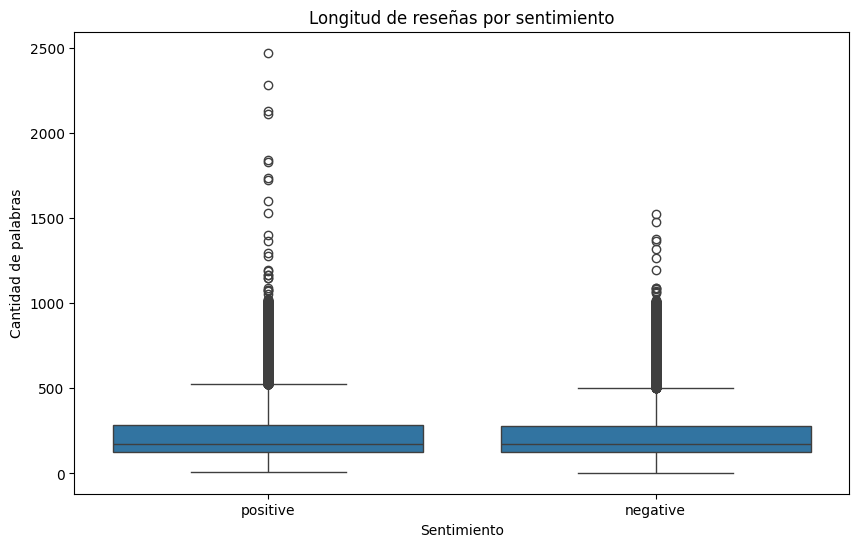

In [29]:

plt.figure(figsize=(10, 6))

sns.boxplot(data=df, x='sentiment', y='longitud')

plt.title('Longitud de reseñas por sentimiento')
plt.xlabel('Sentimiento')
plt.ylabel('Cantidad de palabras')

plt.show()


In [30]:

print(df.groupby('sentiment')['longitud'].mean())


sentiment
negative    229.46456
positive    232.84932
Name: longitud, dtype: float64



### Interpretacion de la exploracion

El conjunto de datos contiene 50.000 reseñas de peliculas y dos columnas principales: review y sentiment.

Se identificaron 25.000 reseñas positivas y 25.000 negativas, por lo que el conjunto de datos se encuentra balanceado.

Tambien se verificaron los valores nulos y se comprobo que no existen datos faltantes.

Se realizo una revision de reseñas duplicadas y se calculo la longitud de cada reseña para comparar la cantidad de palabras entre sentimientos positivos y negativos.


N2-----


In [31]:

df = df.sample(n=5000, random_state=42)

df = df.reset_index(drop=True)

print("Cantidad de registros:", len(df))

df.head()


Cantidad de registros: 5000


,review,sentiment,longitud
0,"I really liked this Summerslam due to the look of the arena, the curtains and just the look overall was interesting to me for some reason. Anyways, this could have been one of the best Summerslam'...",positive,201
1,Not many television shows appeal to quite as many different kinds of fans like Farscape does...I know youngsters and 30/40+ years old;fans both Male and Female in as many different countries as yo...,positive,354
2,"The film quickly gets to a major chase scene with ever increasing destruction. The first really bad thing is the guy hijacking Steven Seagal would have been beaten to pulp by Seagal's driving, but...",negative,119
3,"Jane Austen would definitely approve of this one!<br /><br />Gwyneth Paltrow does an awesome job capturing the attitude of Emma. She is funny without being excessively silly, yet elegant. She puts...",positive,99
4,"Expectations were somewhat high for me when I went to see this movie, after all I thought Steve Carell could do no wrong coming off of great movies like Anchorman, The 40 Year-Old Virgin, and Litt...",negative,332


In [32]:

for i in range(3):
    print("Reseña", i+1)
    print(df['review'][i])
    print("--------------------------")


Reseña 1
I really liked this Summerslam due to the look of the arena, the curtains and just the look overall was interesting to me for some reason. Anyways, this could have been one of the best Summerslam's ever if the WWF didn't have Lex Luger in the main event against Yokozuna, now for it's time it was ok to have a huge fat man vs a strong man but I'm glad times have changed. It was a terrible main event just like every match Luger is in is terrible. Other matches on the card were Razor Ramon vs Ted Dibiase, Steiner Brothers vs Heavenly Bodies, Shawn Michaels vs Curt Hening, this was the event where Shawn named his big monster of a body guard Diesel, IRS vs 1-2-3 Kid, Bret Hart first takes on Doink then takes on Jerry Lawler and stuff with the Harts and Lawler was always very interesting, then Ludvig Borga destroyed Marty Jannetty, Undertaker took on Giant Gonzalez in another terrible match, The Smoking Gunns and Tatanka took on Bam Bam Bigelow and the Headshrinkers, and Yokozuna def

In [33]:

stop_words = set(stopwords.words('english'))

stop_words.remove('not')
stop_words.remove('no')
stop_words.remove('but')

stemmer = PorterStemmer()

print("Palabras que conservaremos:")
print("not, no, but")


Palabras que conservaremos:
not, no, but


In [34]:

def limpiar_texto(texto):

    texto = texto.lower()

    texto = re.sub(r'<.*?>', '', texto)

    texto = re.sub(r'[^a-z\s]', '', texto)

    palabras = texto.split()

    palabras_limpias = []

    for palabra in palabras:
        if palabra not in stop_words:
            palabra = stemmer.stem(palabra)
            palabras_limpias.append(palabra)

    return ' '.join(palabras_limpias)


In [35]:

df['review_clean'] = df['review'].apply(limpiar_texto)

df[['review', 'review_clean', 'sentiment']].head()


,review,review_clean,sentiment
0,"I really liked this Summerslam due to the look of the arena, the curtains and just the look overall was interesting to me for some reason. Anyways, this could have been one of the best Summerslam'...",realli like summerslam due look arena curtain look overal interest reason anyway could one best summerslam ever wwf didnt lex luger main event yokozuna time ok huge fat man vs strong man but im gl...,positive
1,Not many television shows appeal to quite as many different kinds of fans like Farscape does...I know youngsters and 30/40+ years old;fans both Male and Female in as many different countries as yo...,not mani televis show appeal quit mani differ kind fan like farscap doesi know youngster year oldfan male femal mani differ countri think ador tv miniseri element found almost everi show tv charac...,positive
2,"The film quickly gets to a major chase scene with ever increasing destruction. The first really bad thing is the guy hijacking Steven Seagal would have been beaten to pulp by Seagal's driving, but...",film quickli get major chase scene ever increas destruct first realli bad thing guy hijack steven seagal would beaten pulp seagal drive but probabl would end whole premis movieit seem like decid m...,negative
3,"Jane Austen would definitely approve of this one!<br /><br />Gwyneth Paltrow does an awesome job capturing the attitude of Emma. She is funny without being excessively silly, yet elegant. She puts...",jane austen would definit approv onegwyneth paltrow awesom job captur attitud emma funni without excess silli yet eleg put convinc british accent not british mayb im not best judg but fool mesh al...,positive
4,"Expectations were somewhat high for me when I went to see this movie, after all I thought Steve Carell could do no wrong coming off of great movies like Anchorman, The 40 Year-Old Virgin, and Litt...",expect somewhat high went see movi thought steve carel could no wrong come great movi like anchorman yearold virgin littl miss sunshin boy wrongil start right movi certain point steve carel allow ...,negative


In [36]:

print("TEXTO ORIGINAL:")
print(df['review'][0])

print("\nTEXTO LIMPIO:")
print(df['review_clean'][0])


TEXTO ORIGINAL:
I really liked this Summerslam due to the look of the arena, the curtains and just the look overall was interesting to me for some reason. Anyways, this could have been one of the best Summerslam's ever if the WWF didn't have Lex Luger in the main event against Yokozuna, now for it's time it was ok to have a huge fat man vs a strong man but I'm glad times have changed. It was a terrible main event just like every match Luger is in is terrible. Other matches on the card were Razor Ramon vs Ted Dibiase, Steiner Brothers vs Heavenly Bodies, Shawn Michaels vs Curt Hening, this was the event where Shawn named his big monster of a body guard Diesel, IRS vs 1-2-3 Kid, Bret Hart first takes on Doink then takes on Jerry Lawler and stuff with the Harts and Lawler was always very interesting, then Ludvig Borga destroyed Marty Jannetty, Undertaker took on Giant Gonzalez in another terrible match, The Smoking Gunns and Tatanka took on Bam Bam Bigelow and the Headshrinkers, and Yokoz

In [37]:

print("Registros procesados:", len(df))

print("\nValores nulos en texto limpio:")
print(df['review_clean'].isnull().sum())

print("\nEjemplo de texto limpio:")
print(df['review_clean'].iloc[0])


Registros procesados: 5000

Valores nulos en texto limpio:
0

Ejemplo de texto limpio:
realli like summerslam due look arena curtain look overal interest reason anyway could one best summerslam ever wwf didnt lex luger main event yokozuna time ok huge fat man vs strong man but im glad time chang terribl main event like everi match luger terribl match card razor ramon vs ted dibias steiner brother vs heavenli bodi shawn michael vs curt hene event shawn name big monster bodi guard diesel ir vs kid bret hart first take doink take jerri lawler stuff hart lawler alway interest ludvig borga destroy marti jannetti undertak took giant gonzalez anoth terribl match smoke gunn tatanka took bam bam bigelow headshrink yokozuna defend world titl lex luger match bore terribl end howev deserv



### Interpretacion del preprocesamiento

Para preparar los datos se selecciono una muestra de 5.000 reseñas.

Se realizo la limpieza del texto convirtiendo las letras a minusculas, eliminando etiquetas HTML, signos de puntuacion y caracteres especiales.

Tambien se eliminaron palabras comunes en ingles mediante stopwords y se aplico stemming para reducir las palabras a su raiz.

Se decidio conservar las palabras not, no y but porque pueden cambiar el significado de una opinion. Esto es importante para el analisis de sentimientos, ya que una negacion puede convertir una expresion positiva en negativa.


N3------


In [38]:

X = df['review_clean']
y = df['sentiment']

print("Variable independiente (X):")
print(X.head())

print("\nVariable dependiente (y):")
print(y.head())


Variable independiente (X):
0    realli like summerslam due look arena curtain look overal interest reason anyway could one best summerslam ever wwf didnt lex luger main event yokozuna time ok huge fat man vs strong man but im gl...
1    not mani televis show appeal quit mani differ kind fan like farscap doesi know youngster year oldfan male femal mani differ countri think ador tv miniseri element found almost everi show tv charac...
2    film quickli get major chase scene ever increas destruct first realli bad thing guy hijack steven seagal would beaten pulp seagal drive but probabl would end whole premis movieit seem like decid m...
3    jane austen would definit approv onegwyneth paltrow awesom job captur attitud emma funni without excess silli yet eleg put convinc british accent not british mayb im not best judg but fool mesh al...
4    expect somewhat high went see movi thought steve carel could no wrong come great movi like anchorman yearold virgin littl miss sunshin boy wrongil 

In [39]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Datos de entrenamiento:", len(X_train))
print("Datos de prueba:", len(X_test))


Datos de entrenamiento: 4000
Datos de prueba: 1000


In [40]:

print("Distribucion de entrenamiento:")
print(y_train.value_counts())

print("\nDistribucion de prueba:")
print(y_test.value_counts())


Distribucion de entrenamiento:
sentiment
positive    2015
negative    1985
Name: count, dtype: int64

Distribucion de prueba:
sentiment
positive    504
negative    496
Name: count, dtype: int64


In [41]:

print("Porcentaje de entrenamiento:",
      len(X_train) / len(X) * 100, "%")

print("Porcentaje de prueba:",
      len(X_test) / len(X) * 100, "%")


Porcentaje de entrenamiento: 80.0 %
Porcentaje de prueba: 20.0 %



### Interpretacion de la division de datos

Se dividio el conjunto de datos en dos partes: 80% para entrenamiento y 20% para prueba.

Se utilizo train_test_split para realizar la division, con random_state=42 para mantener los mismos resultados en cada ejecucion.

Tambien se utilizo stratify=y para conservar la proporcion de reseñas positivas y negativas en ambos grupos.

Los datos de entrenamiento serviran para que el modelo aprenda patrones del texto, mientras que los datos de prueba permitiran evaluar su capacidad para clasificar reseñas que no utilizo durante el entrenamiento.


N4-------


### ¿Que es TF-IDF?

TF-IDF es una tecnica que permite calcular la importancia de las palabras dentro de un documento.

Toma en cuenta la frecuencia de una palabra en una reseña y tambien que tan frecuente aparece en el conjunto de documentos.

Las palabras que aparecen en casi todas las reseñas reciben menor importancia, mientras que las palabras mas representativas pueden recibir mayor peso.

A diferencia de Bag of Words, que cuenta cuantas veces aparece cada palabra, TF-IDF asigna un peso segun su importancia.


In [42]:

vectorizador_bow = CountVectorizer(max_features=5000)

X_train_bow = vectorizador_bow.fit_transform(X_train)

X_test_bow = vectorizador_bow.transform(X_test)

print("Matriz de entrenamiento:", X_train_bow.shape)
print("Matriz de prueba:", X_test_bow.shape)
print("Cantidad de palabras:", len(vectorizador_bow.get_feature_names_out()))


Matriz de entrenamiento: (4000, 5000)
Matriz de prueba: (1000, 5000)
Cantidad de palabras: 5000


In [43]:

print(vectorizador_bow.get_feature_names_out()[:30])


['abandon' 'abba' 'abbey' 'abbott' 'abc' 'abduct' 'abil' 'abl' 'abomin'
 'abort' 'abraham' 'abrupt' 'absenc' 'absent' 'absolut' 'absorb' 'absurd'
 'abund' 'abus' 'abysm' 'academi' 'accent' 'accept' 'access' 'accid'
 'accident' 'acclaim' 'accompani' 'accomplish' 'accord']


In [44]:

vectorizador_tfidf = TfidfVectorizer(max_features=5000)

X_train_tfidf = vectorizador_tfidf.fit_transform(X_train)

X_test_tfidf = vectorizador_tfidf.transform(X_test)

print("Matriz de entrenamiento:", X_train_tfidf.shape)
print("Matriz de prueba:", X_test_tfidf.shape)
print("Cantidad de palabras:", len(vectorizador_tfidf.get_feature_names_out()))


Matriz de entrenamiento: (4000, 5000)
Matriz de prueba: (1000, 5000)
Cantidad de palabras: 5000


In [45]:

print(vectorizador_tfidf.get_feature_names_out()[:30])


['abandon' 'abba' 'abbey' 'abbott' 'abc' 'abduct' 'abil' 'abl' 'abomin'
 'abort' 'abraham' 'abrupt' 'absenc' 'absent' 'absolut' 'absorb' 'absurd'
 'abund' 'abus' 'abysm' 'academi' 'accent' 'accept' 'access' 'accid'
 'accident' 'acclaim' 'accompani' 'accomplish' 'accord']


In [46]:

vectorizador_1000 = CountVectorizer(max_features=1000)

vectorizador_5000 = CountVectorizer(max_features=5000)

datos_1000 = vectorizador_1000.fit_transform(X_train)

datos_5000 = vectorizador_5000.fit_transform(X_train)

print("Con 1000 caracteristicas:", datos_1000.shape)
print("Con 5000 caracteristicas:", datos_5000.shape)


Con 1000 caracteristicas: (4000, 1000)
Con 5000 caracteristicas: (4000, 5000)


In [47]:

print("COMPARACION DE VECTORIZADORES")

print("\nBag of Words:")
print("Caracteristicas:", X_train_bow.shape[1])

print("\nTF-IDF:")
print("Caracteristicas:", X_train_tfidf.shape[1])

print("\nCantidad de documentos:")
print("Entrenamiento:", X_train.shape[0])
print("Prueba:", X_test.shape[0])


COMPARACION DE VECTORIZADORES

Bag of Words:
Caracteristicas: 5000

TF-IDF:
Caracteristicas: 5000

Cantidad de documentos:
Entrenamiento: 4000
Prueba: 1000



### Interpretacion de la vectorizacion

Se utilizaron dos tecnicas para transformar las reseñas en datos numericos.

El primer modelo utiliza Bag of Words mediante CountVectorizer, que representa las palabras segun la cantidad de veces que aparecen en cada reseña.

El segundo modelo utiliza TF-IDF mediante TfidfVectorizer, que asigna pesos a las palabras segun su importancia dentro de los documentos.

En ambos casos se utilizaron hasta 5000 caracteristicas.

Tambien se experimento con el parametro max_features, comparando 1000 y 5000 caracteristicas. Al aumentar este valor se permite representar una mayor cantidad de palabras, aunque tambien aumenta el tamaño de la matriz.

Los vectorizadores fueron ajustados solamente con los datos de entrenamiento para evitar utilizar informacion del conjunto de prueba.


N5------


In [48]:

modelo_bow = LogisticRegression(max_iter=1000)

modelo_bow.fit(X_train_bow, y_train)

print("Modelo Bag of Words entrenado correctamente")


Modelo Bag of Words entrenado correctamente


In [49]:

pred_bow = modelo_bow.predict(X_test_bow)

print("Primeras 10 predicciones:")
print(pred_bow[:10])


Primeras 10 predicciones:
['negative' 'negative' 'negative' 'positive' 'negative' 'positive'
 'negative' 'positive' 'negative' 'negative']


In [50]:

accuracy_bow = accuracy_score(y_test, pred_bow)
precision_bow = precision_score(y_test, pred_bow, pos_label='positive')
recall_bow = recall_score(y_test, pred_bow, pos_label='positive')
f1_bow = f1_score(y_test, pred_bow, pos_label='positive')

print("RESULTADOS BAG OF WORDS")
print("Exactitud:", accuracy_bow)
print("Precision:", precision_bow)
print("Recall:", recall_bow)
print("F1:", f1_bow)


RESULTADOS BAG OF WORDS
Exactitud: 0.846
Precision: 0.8571428571428571
Recall: 0.8333333333333334
F1: 0.8450704225352113


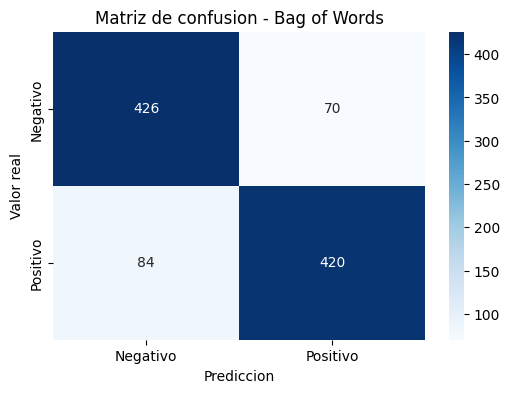

In [51]:

matriz_bow = confusion_matrix(
    y_test,
    pred_bow,
    labels=['negative', 'positive']
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    matriz_bow,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Negativo', 'Positivo'],
    yticklabels=['Negativo', 'Positivo']
)

plt.title('Matriz de confusion - Bag of Words')
plt.xlabel('Prediccion')
plt.ylabel('Valor real')

plt.show()


In [52]:

modelo_tfidf = LogisticRegression(max_iter=1000)

modelo_tfidf.fit(X_train_tfidf, y_train)

print("Modelo TF-IDF entrenado correctamente")


Modelo TF-IDF entrenado correctamente


In [53]:

pred_tfidf = modelo_tfidf.predict(X_test_tfidf)

print("Primeras 10 predicciones:")
print(pred_tfidf[:10])


Primeras 10 predicciones:
['negative' 'negative' 'negative' 'positive' 'positive' 'positive'
 'negative' 'positive' 'negative' 'negative']


In [54]:

accuracy_tfidf = accuracy_score(y_test, pred_tfidf)
precision_tfidf = precision_score(y_test, pred_tfidf, pos_label='positive')
recall_tfidf = recall_score(y_test, pred_tfidf, pos_label='positive')
f1_tfidf = f1_score(y_test, pred_tfidf, pos_label='positive')

print("RESULTADOS TF-IDF")
print("Exactitud:", accuracy_tfidf)
print("Precision:", precision_tfidf)
print("Recall:", recall_tfidf)
print("F1:", f1_tfidf)


RESULTADOS TF-IDF
Exactitud: 0.862
Precision: 0.8560311284046692
Recall: 0.873015873015873
F1: 0.8644400785854617


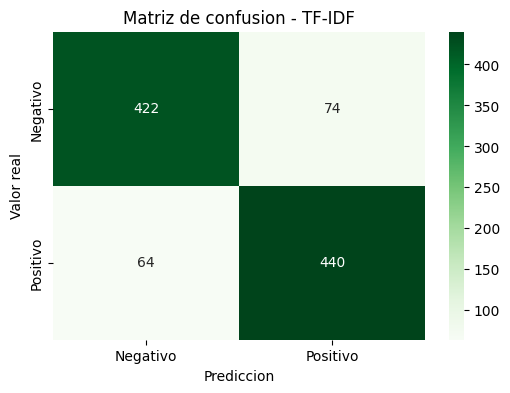

In [55]:

matriz_tfidf = confusion_matrix(
    y_test,
    pred_tfidf,
    labels=['negative', 'positive']
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    matriz_tfidf,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Negativo', 'Positivo'],
    yticklabels=['Negativo', 'Positivo']
)

plt.title('Matriz de confusion - TF-IDF')
plt.xlabel('Prediccion')
plt.ylabel('Valor real')

plt.show()


In [56]:

resultados = pd.DataFrame({
    'Modelo': ['Bag of Words', 'TF-IDF'],
    'Exactitud': [accuracy_bow, accuracy_tfidf],
    'Precision': [precision_bow, precision_tfidf],
    'Recall': [recall_bow, recall_tfidf],
    'F1': [f1_bow, f1_tfidf]
})

resultados


,Modelo,Exactitud,Precision,Recall,F1
0,Bag of Words,0.846,0.857143,0.833333,0.84507
1,TF-IDF,0.862,0.856031,0.873016,0.86444


In [57]:

if f1_bow > f1_tfidf:
    mejor_modelo = modelo_bow
    mejor_nombre = "Bag of Words"
    mejores_predicciones = pred_bow
    print("El mejor modelo es Bag of Words")

elif f1_tfidf > f1_bow:
    mejor_modelo = modelo_tfidf
    mejor_nombre = "TF-IDF"
    mejores_predicciones = pred_tfidf
    print("El mejor modelo es TF-IDF")

else:
    mejor_modelo = modelo_tfidf
    mejor_nombre = "TF-IDF"
    mejores_predicciones = pred_tfidf
    print("Ambos modelos tienen el mismo F1")

print("Modelo seleccionado:", mejor_nombre)


El mejor modelo es TF-IDF
Modelo seleccionado: TF-IDF



### Interpretacion del entrenamiento y evaluacion

Se entrenaron dos modelos de Regresion Logistica utilizando diferentes tecnicas de vectorizacion.

El primer modelo utilizo Bag of Words y el segundo utilizo TF-IDF.

Ambos modelos fueron evaluados utilizando las metricas de exactitud, precision, recall y F1. Tambien se generaron matrices de confusion para observar las clasificaciones correctas e incorrectas.

Finalmente, se compararon los resultados mediante una tabla para identificar cual de los dos modelos obtuvo un mejor rendimiento.

Se selecciono el modelo con mejor valor F1, debido a que esta metrica permite evaluar el equilibrio entre precision y recall.


N6-----------


In [58]:

if mejor_nombre == "Bag of Words":
    mejor_vectorizador = vectorizador_bow
else:
    mejor_vectorizador = vectorizador_tfidf

print("Modelo seleccionado:", mejor_nombre)


Modelo seleccionado: TF-IDF


In [59]:

palabras = mejor_vectorizador.get_feature_names_out()

coeficientes = mejor_modelo.coef_[0]

tabla_palabras = pd.DataFrame({
    'Palabra': palabras,
    'Coeficiente': coeficientes
})

print("15 PALABRAS MAS POSITIVAS")
print(tabla_palabras.sort_values(
    by='Coeficiente', ascending=False
).head(15))

print("\n15 PALABRAS MAS NEGATIVAS")
print(tabla_palabras.sort_values(
    by='Coeficiente', ascending=True
).head(15))


15 PALABRAS MAS POSITIVAS
      Palabra  Coeficiente
1927    great     3.987004
389      best     3.718026
2658     love     2.895016
1525    excel     2.638173
139      amaz     2.371099
4868     well     2.296992
1454    enjoy     2.212639
1618  favorit     2.100761
1788      fun     2.064175
4233    still     2.058787
130      also     1.962943
357    beauti     1.949073
3252  perfect     1.912530
2594     life     1.624515
4525    today     1.556924

15 PALABRAS MAS NEGATIVAS
      Palabra  Coeficiente
305       bad    -4.892896
4948    worst    -4.061529
4842     wast    -3.385985
3026       no    -3.355798
287        aw    -2.764880
4287   stupid    -2.571581
4447  terribl    -2.518284
471      bore    -2.505310
3054     noth    -2.494610
3346     poor    -2.482310
2134  horribl    -2.331780
39        act    -2.267996
4947     wors    -2.240000
1504     even    -2.057692
2849    minut    -2.019511


In [60]:

resenas = [
    "This movie was amazing, beautiful and wonderful. I really loved it.",
    "This movie was terrible, boring and disappointing. I hated it.",
    "The movie was okay, but I expected something much better."
]

resenas_limpias = [limpiar_texto(texto) for texto in resenas]

datos_resenas = mejor_vectorizador.transform(resenas_limpias)

print("Reseñas preparadas correctamente")


Reseñas preparadas correctamente


In [61]:

predicciones = mejor_modelo.predict(datos_resenas)

probabilidades = mejor_modelo.predict_proba(datos_resenas)

for i in range(3):
    print("Reseña:", resenas[i])
    print("Sentimiento predicho:", predicciones[i])
    print("Probabilidad negativa:", round(probabilidades[i][0] * 100, 2), "%")
    print("Probabilidad positiva:", round(probabilidades[i][1] * 100, 2), "%")
    print("------------------------------")


Reseña: This movie was amazing, beautiful and wonderful. I really loved it.
Sentimiento predicho: positive
Probabilidad negativa: 2.04 %
Probabilidad positiva: 97.96 %
------------------------------
Reseña: This movie was terrible, boring and disappointing. I hated it.
Sentimiento predicho: negative
Probabilidad negativa: 95.42 %
Probabilidad positiva: 4.58 %
------------------------------
Reseña: The movie was okay, but I expected something much better.
Sentimiento predicho: negative
Probabilidad negativa: 83.26 %
Probabilidad positiva: 16.74 %
------------------------------


In [62]:

errores = pd.DataFrame({
    'Reseña': X_test,
    'Real': y_test,
    'Prediccion': mejores_predicciones
})

errores = errores[errores['Real'] != errores['Prediccion']]

print("Cantidad de reseñas mal clasificadas:", len(errores))

errores.head(2)


Cantidad de reseñas mal clasificadas: 138


,Reseña,Real,Prediccion
3534,must warn spoiler but start got spanish judg februari think mention last copi but see wasnt backord but either way thought good want see mainli great actor matthew lillard im surpris no one review...,positive,negative
2793,cia analyst dougla freeman gyllenha get see first secret locat interrog anwar metwal accus contact known terrorist bomb maker anwar wife witherspoon frantic regard whereabout husband dont hate tit...,positive,negative


In [63]:

for i, fila in errores.head(2).iterrows():
    print("RESEÑA:")
    print(df.loc[i, 'review'])

    print("\nSentimiento real:", fila['Real'])
    print("Sentimiento predicho:", fila['Prediccion'])
    print("------------------------------")


RESEÑA:
I must warn you, there are some spoilers in it. But to start it off, I got "Spanish Judges" on February I think. It was mention it was the last copy, but as I see, it wasn't back-ordered. But either way, I have it. I thought it was good. I wanted to see this mainly because of the great actor, Matthew Lillard (I'm surprised no one on the reviews mention the scar) although it is kind of low budget, getting enough money to make this film would be worth spending. Man, what a good actor.<br /><br />The story it about a con artist known as Jack (Matthew Lillard) who "claims" to have merchandises called The Spanish Judges. If you don't know what Spanish Judges are or haven't seen the trailer for this and this is the first review you have read, I won't even say what they are. I figure it would be a big twist of no one knew what it was. He needs protection, so he hires a couple who are also crooks, Max and Jamie (Vincent D'Onofrio and Valeria Golino) as well as a crook that goes by the 


### Analisis de reseñas mal clasificadas

Se seleccionaron dos reseñas que fueron clasificadas incorrectamente por el modelo.

Estos errores pueden producirse porque algunas opiniones contienen sarcasmo, contradicciones o expresiones cuyo significado depende del contexto.

El modelo utiliza las palabras y los patrones aprendidos durante el entrenamiento, pero no siempre logra comprender completamente la intencion del usuario.

Por esta razon, algunas reseñas pueden ser clasificadas de manera incorrecta.



# CONCLUSIONES

En este trabajo se desarrollo un modelo de analisis de sentimientos utilizando Regresion Logistica para clasificar reseñas de peliculas como positivas o negativas.

Se realizo la exploracion del conjunto de datos, el preprocesamiento del texto, la division de los datos y la vectorizacion mediante Bag of Words y TF-IDF.

Posteriormente, se entrenaron y evaluaron ambos modelos utilizando las metricas de exactitud, precision, recall y F1.

Se compararon los resultados para seleccionar el modelo con mejor rendimiento.

Finalmente, se analizaron los coeficientes de las palabras, se realizaron predicciones con reseñas propias y se identificaron algunos errores de clasificacion.

Con este trabajo se pudo comprobar como las tecnicas de procesamiento de lenguaje natural y el aprendizaje automatico permiten realizar clasificaciones de sentimientos a partir de textos.
